In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
orders = pd.read_csv(
    "../data/cleaned/orders_clean.csv",
    parse_dates=["order_purchase_timestamp"]
)

order_items = pd.read_csv("../data/cleaned/order_items_clean.csv")
products = pd.read_csv("../data/cleaned/products_clean.csv")

In [4]:
category_sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_revenue = (
    category_sales
    .groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

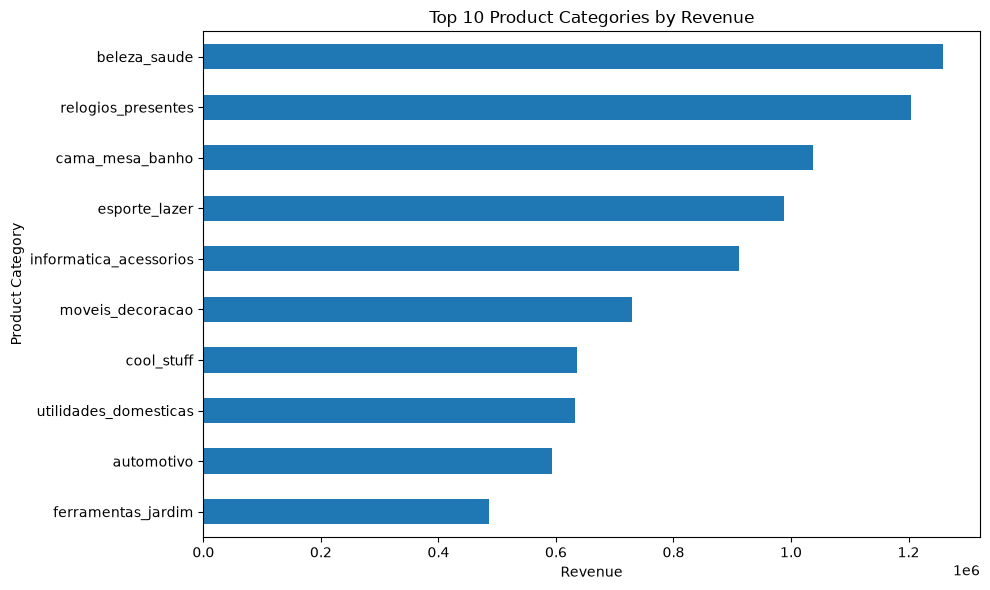

In [5]:
top_10_categories = category_revenue.head(10)

top_10_categories.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [6]:
orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_revenue = (
    orders
    .groupby("order_month")["order_value"]
    .sum()
)

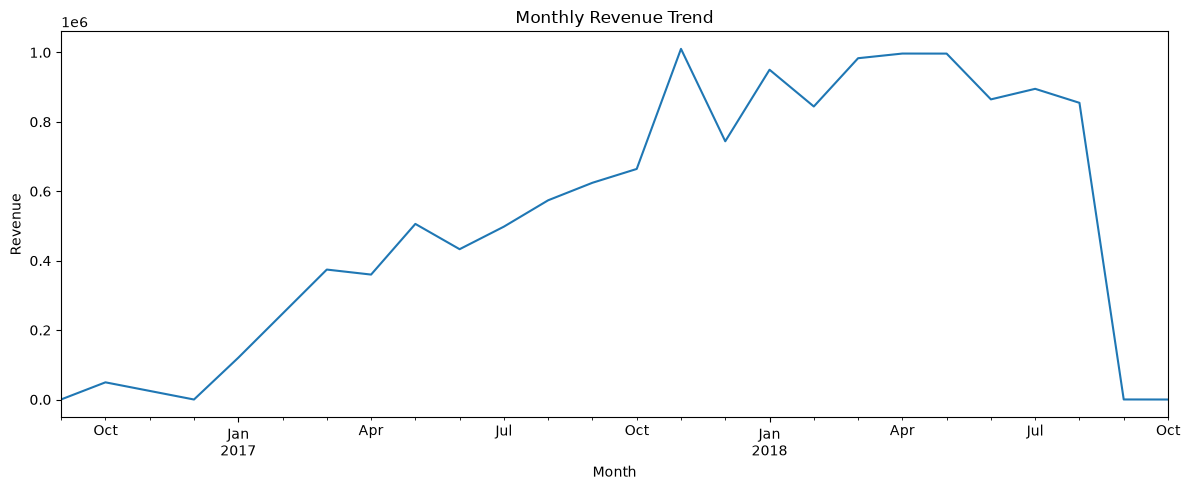

In [7]:
monthly_revenue.plot(
    kind="line",
    figsize=(12, 5)
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [9]:
customers = pd.read_csv("../data/cleaned/customers_clean.csv")

In [10]:
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

customer_order_count = (
    customer_orders
    .groupby("customer_unique_id")["order_id"]
    .count()
)

In [11]:
customer_type = customer_order_count.apply(
    lambda x: "repeat" if x > 1 else "one_time"
)

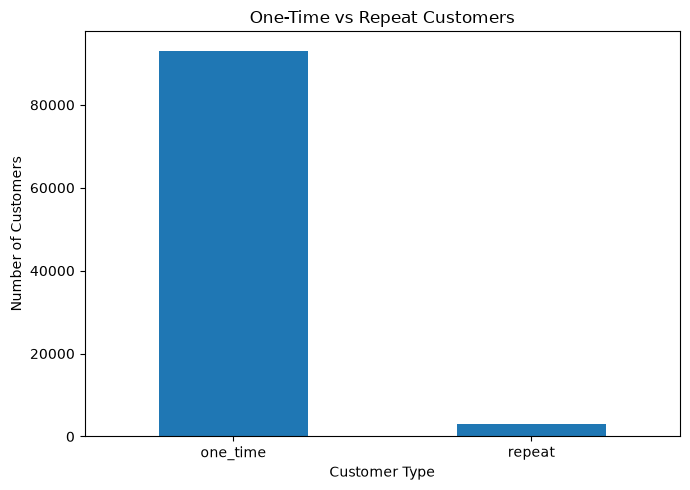

In [12]:
customer_counts = customer_type.value_counts()

customer_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
customer_value = (
    customer_orders
    .groupby("customer_unique_id")["order_value"]
    .sum()
    .reset_index()
)

customer_value["customer_type"] = customer_value[
    "customer_unique_id"
].map(customer_type)

average_revenue = (
    customer_value
    .groupby("customer_type")["order_value"]
    .mean()
)

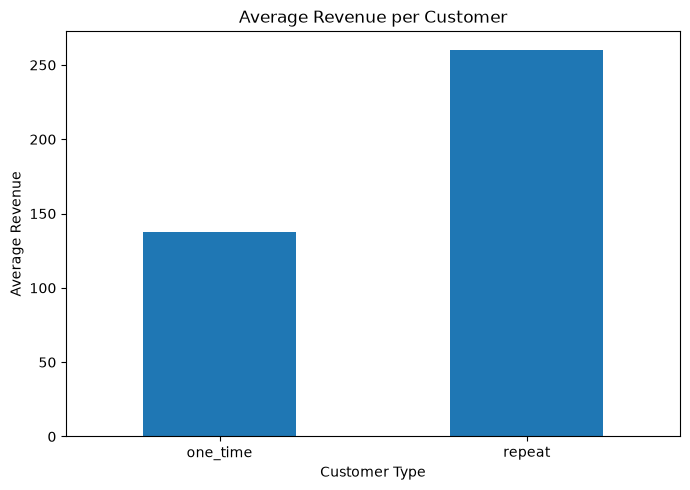

In [14]:
average_revenue.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Revenue per Customer")
plt.xlabel("Customer Type")
plt.ylabel("Average Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
reviews = pd.read_csv("../data/cleaned/reviews_clean.csv")

In [17]:
delivery_reviews = orders.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

delivery_review_score = (
    delivery_reviews
    .groupby("late_delivery")["review_score"]
    .mean()
)

delivery_review_score.index = [
    "On Time" if x == False else "Late"
    for x in delivery_review_score.index
]

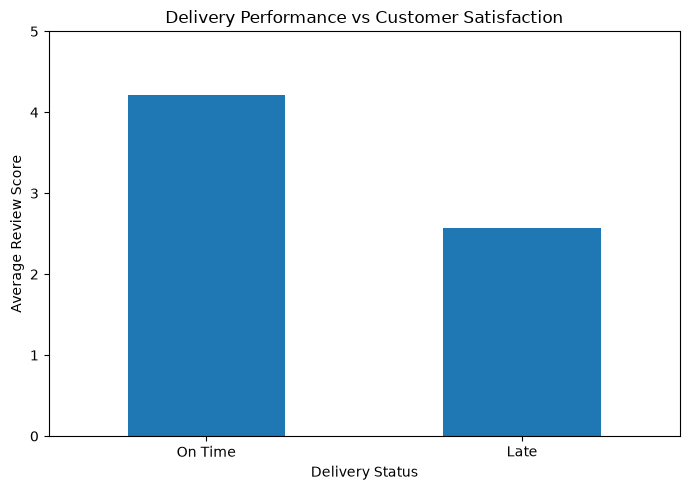

In [18]:
delivery_review_score.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Delivery Performance vs Customer Satisfaction")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()